In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras.datasets.fashion_mnist import load_data
from keras.layers import Dense, BatchNormalization, Reshape, Conv2DTranspose, LeakyReLU, Flatten, Dropout, Conv2D

In [2]:
data = load_data()
(x_train, y_train), (x_test, y_test) = data

In [3]:
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")
x_train = (x_train - 127.5) / 127.5
x_test = (x_test - 127.5) / 127.5
x_train = x_train.reshape((-1, 28, 28, 1))
x_test = x_test.reshape((-1, 28, 28, 1))

In [4]:
latent_dim = 100

generator_input = keras.Input(shape=(latent_dim,), name="noise")

x = Dense(7 * 7 * 128, use_bias=False)(generator_input)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.2)(x)

x = Reshape((7, 7, 128))(x)

x = Conv2DTranspose(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.2)(x)

x = Conv2DTranspose(1, kernel_size=4, strides=2, padding="same", activation="tanh")(x)

generator = keras.Model(generator_input, x, name="generator")

generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noise (InputLayer)              │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [5]:
discriminator_input = keras.Input(shape=(28, 28, 1), name="image")

x = Conv2D(64, kernel_size=4, strides=2, padding="same")(discriminator_input)
x = LeakyReLU(negative_slope=0.2)(x)
x = Dropout(0.3)(x)

x = Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = LeakyReLU(negative_slope=0.2)(x)
x = Dropout(0.3)(x)

x = Flatten()(x)
discriminator_output = Dense(1, activation="sigmoid")(x)

discriminator = keras.Model(
    discriminator_input, discriminator_output, name="discriminator"
)

discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
discriminator.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.5
    ),
    loss=keras.losses.BinaryCrossentropy()
)

In [7]:
gan_input = keras.Input(
    shape=(latent_dim,),
    name="gan_noise"
)

generated_image = generator(gan_input)
gan_output = discriminator(generated_image)

gan = keras.Model(
    gan_input,
    gan_output,
    name="gan"
)

gan.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.5
    ),
    loss="binary_crossentropy"
)

gan.summary()

Model: "gan"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gan_noise (InputLayer)          │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ generator (Functional)          │ (None, 28, 28, 1)      │       784,641 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ discriminator (Functional)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 923,202 (3.52 MB)

 Trainable params: 910,530 (3.47 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [ ]:
batch_size = 128
epochs = 50
for epoch in range(epochs):

    indices = np.random.permutation(len(x_train))
    shuffled_images = x_train[indices]

    d_losses = []
    g_losses = []
    mini_batch = 1
    for start in range(0, len(x_train) - batch_size + 1, batch_size):

        real_images = shuffled_images[start : start + batch_size]

        noise = tf.random.normal((batch_size, latent_dim))

        fake_images = generator(noise, training=False)

        real_labels = np.ones((batch_size, 1), dtype="float32") * 0.9

        fake_labels = np.zeros((batch_size, 1), dtype="float32")

        discriminator.trainable = True
        
        d_loss_real = discriminator.train_on_batch(real_images, real_labels)

        d_loss_fake = discriminator.train_on_batch(fake_images, fake_labels)
        
        discriminator.trainable = False

        d_loss = (
            float(np.asarray(d_loss_real).mean())
            + float(np.asarray(d_loss_fake).mean())
        ) / 2

        noise = tf.random.normal((batch_size, latent_dim))

        misleading_labels = np.ones((batch_size, 1), dtype="float32")

        g_loss = gan.train_on_batch(noise, misleading_labels)

        g_loss = float(np.asarray(g_loss).mean())

        d_losses.append(d_loss)
        g_losses.append(g_loss)
        print("mini batch:", mini_batch, "/", 60000 / batch_size)
        mini_batch = mini_batch + 1

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"D Loss: {np.mean(d_losses):.4f} | "
        f"G Loss: {np.mean(g_losses):.4f}"
    )

In [ ]:
noise = tf.random.normal((80, latent_dim))

generated_images = generator(
    noise,
    training=False
).numpy()

# تبدیل محدوده [-1, 1] به [0, 1] برای نمایش
generated_images = (generated_images + 1) / 2

fig, axes = plt.subplots(10, 8, figsize=(16, 16))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i, :, :, 0], cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
model = keras.models.load_model("MyModel.keras")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


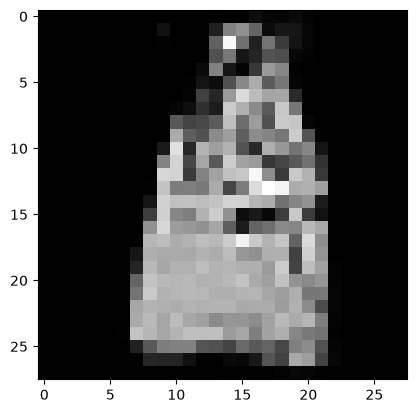

In [57]:
noise = tf.random.normal((1, latent_dim))
generated_image = model.predict(noise)
plt.imshow(generated_image[0, :, :, 0], cmap="gray")